In [43]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
import numpy as np
import random
import re
import unicodedata
from torch.utils.data import Dataset, DataLoader
import csv
from collections import Counter
import ast
import matplotlib.ticker as ticker
import time
import math
import matplotlib.pyplot as plt
import pandas as pd, ast, re
import nltk
from torch.nn.utils.rnn import pad_sequence

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
!wget http://nlp.stanford.edu/data/glove.6B.zip
!unzip -o glove.6B.zip

--2025-05-23 04:42:38--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2025-05-23 04:42:38--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2025-05-23 04:42:38--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [66]:
def parse_list_column(col):
    try:
        return ast.literal_eval(col) if isinstance(col, str) and col.startswith('[') else []
    except Exception:
        return []

def preprocess_ingredients(ings):
    tokens = []
    for ing in ings:
        tokens.extend(re.findall(r"\b\w+\b", ing.lower()))
    return tokens


def preprocess_recipe(recipe):
    sentences = []
    for step in recipe:
        sentences.extend([sent.strip().lower() for sent in re.split(r'[.!?]', step) if sent.strip()])
    return sentences

def build_vocab(sequences):
    counter = Counter(w for seq in sequences for w in seq)
    vocab = {'PAD': 0, 'SOS': 1, 'EOS': 2, 'UNK': 3}
    idx = 4
    for word, _ in counter.most_common():
        vocab[word] = idx
        idx += 1
    return vocab


def indexes_from_sentence(vocab, sentence):
    return [vocab['SOS']] + [vocab.get(word, vocab['UNK']) for word in sentence] + [vocab['EOS']]

def tensor_from_sentence(vocab, sentence, max_len=None):
    indexes = indexes_from_sentence(vocab, sentence)
    return torch.tensor(indexes, dtype=torch.long)

def tensors_from_pair(pair, ingredient_vocab, recipe_vocab):
    input_tensor = tensor_from_sentence(ingredient_vocab, pair[0])
    target_tensor = tensor_from_sentence(recipe_vocab, pair[1])
    return (input_tensor, target_tensor)

In [67]:
class RecipeDataset(Dataset):
    def __init__(self, pairs, ingredient_vocab, recipe_vocab, max_len):
        self.pairs = pairs
        self.ingredient_vocab = ingredient_vocab
        self.recipe_vocab = recipe_vocab
        self.max_len = max_len
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, idx):
        ing_tokens = self.pairs[idx][0]
        rec_tokens = self.pairs[idx][1]
        inp = tensor_from_sentence(self.ingredient_vocab, ing_tokens, self.max_len)
        out = tensor_from_sentence(self.recipe_vocab, rec_tokens, self.max_len)
        return inp, out

In [46]:
train_df = pd.read_csv("train.csv", nrows=90000)
train_df["Ingredients"] = train_df["Ingredients"].apply(ast.literal_eval)
train_df["Recipe"] = train_df["Recipe"].apply(ast.literal_eval)
# Apply preprocessing
train_df["ingredient_tokens"] = train_df["Ingredients"].apply(preprocess_ingredients)
train_df["recipe_tokens"] = train_df["Recipe"].apply(preprocess_recipe)

# Combine into (input, target) pairs
train_pairs = list(zip(train_df["ingredient_tokens"], train_df["recipe_tokens"]))
ingredient_vocab = build_vocab(train_df["ingredient_tokens"].tolist())
recipe_vocab = build_vocab(train_df["recipe_tokens"].tolist())


# Load and preprocess test.csv
test_df = pd.read_csv("test.csv")
test_df["Ingredients"] = test_df["Ingredients"].apply(ast.literal_eval)
test_df["Recipe"] = test_df["Recipe"].apply(ast.literal_eval)
test_df["ingredient_tokens"] = test_df["Ingredients"].apply(preprocess_ingredients)
test_df["recipe_tokens"] = test_df["Recipe"].apply(preprocess_recipe)

# Create test pairs
test_pairs = list(zip(test_df["ingredient_tokens"], test_df["recipe_tokens"]))

# Convert to tensor pairs
test_tensor_pairs = [tensors_from_pair(pair, ingredient_vocab, recipe_vocab) for pair in test_pairs]


In [47]:
print("Ingredient vocab size:", len(ingredient_vocab))
print("Recipe vocab size:", len(recipe_vocab))

Ingredient vocab size: 7252
Recipe vocab size: 346283


In [48]:
def load_glove_embeddings(glove_file_path, embedding_dim):
    embeddings_index = {}
    with open(glove_file_path, encoding='utf8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            coefs = np.asarray(values[1:], dtype='float32')
            embeddings_index[word] = coefs
    return embeddings_index

embedding_dim = 100
glove_path = "glove.6B.100d.txt"
glove_embeddings = load_glove_embeddings(glove_path, embedding_dim)

def build_embedding_matrix(vocab, embeddings_index, embedding_dim):
    matrix = np.random.normal(scale=0.6, size=(len(vocab), embedding_dim))
    for word, idx in vocab.items():
        if word in embeddings_index:
            matrix[idx] = embeddings_index[word]
    return torch.tensor(matrix, dtype=torch.float32)

ingredient_embedding_matrix = build_embedding_matrix(ingredient_vocab, glove_embeddings, embedding_dim)

In [68]:
class SetEncoder(nn.Module):
    def __init__(self, vocab_size, hidden_size, num_layers=1, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_size, padding_idx=0)
        self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers=num_layers,
                            dropout=dropout if num_layers > 1 else 0, batch_first=True)

    def forward(self, input_seq):
        embedded = self.embedding(input_seq)
        outputs, (hidden, cell) = self.lstm(embedded)  # outputs: (batch, seq_len, hidden)
        return outputs, hidden, cell

class CoverageDecoder(nn.Module):
    def __init__(self, hidden_size, output_size, embedding_dim, num_layers=1, dropout=0.1):
        super().__init__()
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(output_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_size, num_layers=num_layers,
                            dropout=dropout if num_layers > 1 else 0, batch_first=True)
        self.attn = nn.Linear(hidden_size * 2 + 1, 1)  # +1 for coverage
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_step, hidden, cell, encoder_outputs, coverage):
        embedded = self.dropout(self.embedding(input_step))  # (batch, 1, embed)
        output, (hidden, cell) = self.lstm(embedded, (hidden, cell))  # (batch, 1, hidden)

        dec_out = output.squeeze(1)  # (batch, hidden)
        dec_out_exp = dec_out.unsqueeze(1).expand(-1, encoder_outputs.size(1), -1)
        coverage_unsq = coverage.unsqueeze(-1)

        attn_input = torch.cat([encoder_outputs, dec_out_exp, coverage_unsq], dim=2)  # (batch, seq, 2H+1)
        attn_scores = self.attn(attn_input).squeeze(-1)  # (batch, seq_len)
        attn_weights = F.softmax(attn_scores, dim=1)
        context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs).squeeze(1)

        final_output = self.out(dec_out + context)  # fusion
        final_output = F.log_softmax(final_output, dim=1)

        new_coverage = coverage + attn_weights
        return final_output, hidden, cell, attn_weights, new_coverage


In [69]:
def collate_fn(batch):
    inputs, targets = zip(*batch)
    inputs_padded = pad_sequence(inputs, batch_first=True, padding_value=0)
    targets_padded = pad_sequence(targets, batch_first=True, padding_value=0)
    # For copy mechanism, keep a version of the input with correct indices
    return inputs_padded, targets_padded, inputs_padded

max_len = 100
train_dataset = RecipeDataset(train_pairs, ingredient_vocab, recipe_vocab, max_len=max_len)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn)


In [70]:
def train_batch(inputs, targets, src_seqs, encoder, decoder, enc_opt, dec_opt, criterion, lambda_cov=1.0, teacher_forcing_ratio=None):  # Move to device
    inputs, targets = inputs.to(device), targets.to(device)
    batch_size, tgt_len = targets.size()

    # Zero gradients
    enc_opt.zero_grad()
    dec_opt.zero_grad()

    # Encode
    encoder_outputs, hidden, cell = encoder(inputs)

    # Init decoder
    decoder_input = torch.full((batch_size, 1), recipe_vocab['SOS'], dtype=torch.long, device=device)
    coverage = torch.zeros(batch_size, encoder_outputs.size(1), device=device)

    loss = 0
    cov_loss = 0

    for t in range(tgt_len):
        decoder_output, hidden, cell, attn_weights, coverage = decoder(
            decoder_input, hidden, cell, encoder_outputs, coverage
        )

        # Loss
        nll = criterion(decoder_output, targets[:, t])
        cov_loss += torch.sum(torch.min(attn_weights, coverage))
        loss += nll

        # Next input
        use_tf = random.random() < teacher_forcing_ratio
        top1 = decoder_output.argmax(-1, keepdim=True)
        decoder_input = targets[:, t].unsqueeze(1) if use_tf else top1

    # Total loss
    total_loss = loss / tgt_len + lambda_cov * cov_loss / tgt_len
    total_loss.backward()

    # Clip & update
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), max_norm=5)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), max_norm=5)
    enc_opt.step()
    dec_opt.step()

    return total_loss.item()


In [71]:
def get_teacher_forcing_ratio(step):
    return 0.1

In [53]:
def showPlot(points):
    plt.figure(figsize=(8, 5))
    plt.plot(points)
    plt.title("Training Loss")
    plt.xlabel("Iterations (per plot_every)")
    plt.ylabel("Loss")
    plt.grid(True)
    ax = plt.gca()
    loc = ticker.MultipleLocator(base=0.2)
    ax.yaxis.set_major_locator(loc)
    plt.show()


In [72]:
def train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=3):
    encoder.train()
    decoder.train()
    all_losses = []
    enc_opt = torch.optim.Adam(encoder.parameters(), lr=0.001)
    dec_opt = torch.optim.Adam(decoder.parameters(), lr=0.001)
    criterion = nn.NLLLoss(ignore_index=0)

    step = 0
    for epoch in range(1, n_epochs + 1):
        epoch_loss = 0
        for batch_idx, (inputs, targets, src_seqs) in enumerate(train_loader):  # FIXED
            step += 1
            tf_ratio = get_teacher_forcing_ratio(step)
            loss = train_batch(inputs, targets, src_seqs, encoder, decoder, enc_opt, dec_opt, criterion, teacher_forcing_ratio=tf_ratio)

            epoch_loss += loss

        avg_epoch_loss = epoch_loss / len(train_loader)
        all_losses.append(avg_epoch_loss)
        print(f"Epoch {epoch} | TF ratio: {tf_ratio:.2f} | Loss: {avg_epoch_loss:.4f}")

    showPlot(all_losses)
    return all_losses


Epoch 1 | TF ratio: 0.10 | Loss: 25.4336
Epoch 2 | TF ratio: 0.10 | Loss: 24.6784
Epoch 3 | TF ratio: 0.10 | Loss: 24.3104
Epoch 4 | TF ratio: 0.10 | Loss: 23.7797
Epoch 5 | TF ratio: 0.10 | Loss: 23.1661


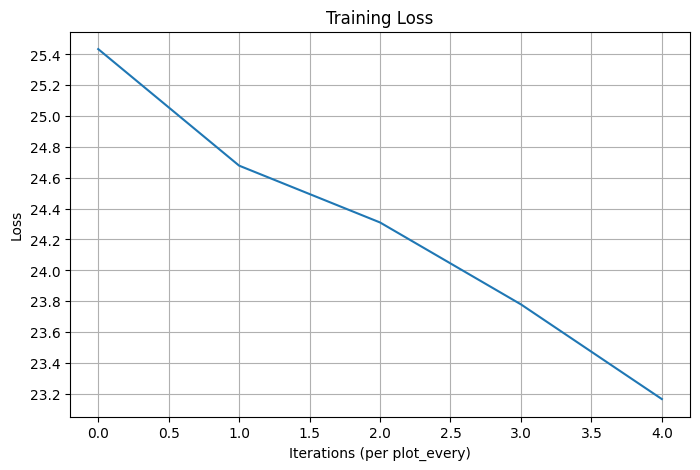

[25.43358301018609,
 24.678432132636175,
 24.3103634830051,
 23.779659764268665,
 23.16610190463596]

In [73]:
num_layers = 2
embedding_dim = 256
hidden_size = 256

# --- Model instantiation ---
encoder = SetEncoder(len(ingredient_vocab), hidden_size=hidden_size, num_layers=num_layers).to(device)
decoder = CoverageDecoder(hidden_size=hidden_size, output_size=len(recipe_vocab),embedding_dim=embedding_dim, num_layers=num_layers).to(device)
train_epochs(train_loader, encoder, decoder, recipe_vocab, n_epochs=5)


In [74]:
def evaluate_model_loss(encoder, decoder, tensor_pairs, criterion, max_length=100):
    total_loss = 0
    with torch.no_grad():
        for input_tensor, target_tensor in tensor_pairs:
            input_tensor = input_tensor.unsqueeze(0).to(device)
            target_tensor = target_tensor.to(device)

            encoder_hidden, encoder_cell = encoder(input_tensor)
            decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
            decoder_hidden = encoder_hidden
            decoder_cell = encoder_cell

            loss = 0
            for di in range(target_tensor.size(0)):
                decoder_output, decoder_hidden, decoder_cell = decoder(decoder_input, decoder_hidden, decoder_cell)
                loss += criterion(decoder_output, target_tensor[di].unsqueeze(0))
                topv, topi = decoder_output.topk(1)
                decoder_input = topi.detach().unsqueeze(1)

                if topi.item() == recipe_vocab['EOS']:
                    break

            total_loss += loss.item() / target_tensor.size(0)

    return total_loss / len(tensor_pairs)


In [75]:
def generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=100):
    input_tensor = input_tensor.unsqueeze(0).to(device)
    encoder_outputs, encoder_hidden, encoder_cell = encoder(input_tensor)

    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
    decoder_hidden = encoder_hidden
    decoder_cell = encoder_cell
    coverage = torch.zeros(encoder_outputs.size(0), encoder_outputs.size(1), device=device)  # (batch, src_len)
    generated_tokens = []

    for _ in range(max_length):
        decoder_output, decoder_hidden, decoder_cell, attn_weights, coverage = decoder(
            decoder_input, decoder_hidden, decoder_cell, encoder_outputs, coverage
        )
        topi = decoder_output.argmax(-1)
        next_token = topi.item()
        if next_token == recipe_vocab['EOS']:
            break
        word = recipe_vocab_inv.get(next_token, "<UNK>")
        generated_tokens.append(word)
        decoder_input = topi.unsqueeze(0)
    return generated_tokens


In [84]:
# Reverse vocab
recipe_vocab_inv = {v: k for k, v in recipe_vocab.items()}

# Print 5 sample outputs
random_indices = random.sample(range(len(test_pairs)), 5)
for i, idx in enumerate(random_indices):
    ingredients_tokens, ground_truth_tokens = test_pairs[idx]
    input_tensor = tensor_from_sentence(ingredient_vocab, ingredients_tokens, max_len)
    generated_tokens = generate_text(encoder, decoder, input_tensor, recipe_vocab, max_length=max_len)

    print(f"--- Example {i+1} (Test Index: {idx}) ---")
    print("Ingredients:", " ".join(ingredients_tokens))
    print("Ground Truth Recipe:", " ".join(ground_truth_tokens))
    print("Generated Recipe:", " ".join(generated_tokens))
    print()

--- Example 1 (Test Index: 497) ---
Ingredients: 1 lb ground beef 3 4 c chopped onion 2 tbsp salad or olive oil 1 1 lb can tomatoes 2 6 oz cans tomato paste 2 c water 1 tbsp chopped parsley 2 tsp salt 4 oz mushroom fresh or canned optional 1 tsp sugar 1 tsp garlic powder 1 2 tsp pepper 1 2 tsp oregano leaves 8 oz lasagna noodles 8 oz mozzarella cheese shredded or thinly sliced 1 lb ricotta or cottage cheese 1 c grated parmesan cheese
Ground Truth Recipe: in large heavy pan, lightly brown beef and onion in oil add tomatoes (put through blender or cut with edge of spoon), paste, water, mushrooms, parsley, salt, sugar, garlic powder, pepper and oregano; simmer uncovered, stirring occasionally, about 30 minutes meanwhile, cook lasagna noodles as directed; drain in 13 x 9 x 2-inch baking pan, spread about 1 cup sauce then alternate layers of lasagna, sauce, ricotta, mozzarella and parmesan cheese, ending with sauce, mozzarella and parmesan
Generated Recipe: SOS brown meat in oil drain

--- 

In [60]:
!pip install nltk bert-score --quiet
!pip install bert-score
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from bert_score import score
import torch
import pandas as pd
import ast, re
from tqdm import tqdm

nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 122.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 100.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 105.6 MB/s eta 0:00:00


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [85]:

def evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab, max_len=100, device='cpu'):
    bleu_scores = []
    meteor_scores = []
    references = []
    candidates = []

    encoder.eval()
    decoder.eval()

    for input_tensor, target_tensor in test_tensor_pairs[:200]:
        input_tensor = input_tensor.unsqueeze(0).to(device)
        target_tensor = target_tensor.to(device)

        with torch.no_grad():
            encoder_outputs, encoder_hidden, encoder_cell = encoder(input_tensor)
            decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=device)
            decoder_hidden = encoder_hidden
            decoder_cell = encoder_cell
            coverage = torch.zeros(encoder_outputs.size(0), encoder_outputs.size(1), device=device)  # (batch, src_len)
            generated_tokens = []

            for _ in range(max_len):
                decoder_output, decoder_hidden, decoder_cell, attn_weights, coverage = decoder(
                    decoder_input, decoder_hidden, decoder_cell, encoder_outputs, coverage
                )
                topi = decoder_output.argmax(-1)
                token_id = topi.squeeze().item()
                if token_id == recipe_vocab['EOS']:
                    break
                word = next((k for k, v in recipe_vocab.items() if v == token_id), "<UNK>")
                generated_tokens.append(word)
                decoder_input = topi.unsqueeze(0)


        reference = [next((k for k, v in recipe_vocab.items() if v == idx.item()), "<UNK>")
                     for idx in target_tensor[1:-1]]
        candidate = generated_tokens

        if reference and candidate:
            smoothie = SmoothingFunction().method4
            bleu = sentence_bleu([reference], candidate, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie)
            meteor = meteor_score([reference], candidate)
            bleu_scores.append(bleu)
            meteor_scores.append(meteor)
            references.append(' '.join(reference))
            candidates.append(' '.join(candidate))

    if candidates and references:
        P, R, F1 = score(candidates, references, lang='en', verbose=False)
        bertscore_f1 = F1.mean().item()
    else:
        bertscore_f1 = 0.0

    print("\n=== Average Scores on Test Set ===")
    print(f"BLEU-4: {sum(bleu_scores)/len(bleu_scores):.4f}" if bleu_scores else "BLEU-4: No valid scores")
    print(f"METEOR: {sum(meteor_scores)/len(meteor_scores):.4f}" if meteor_scores else "METEOR: No valid scores")
    print(f"BERTScore (F1): {bertscore_f1:.4f}")

    encoder.train()
    decoder.train()

evaluate_generated_outputs(test_tensor_pairs, encoder, decoder, recipe_vocab, max_len=100, device=device)

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== Average Scores on Test Set ===
BLEU-4: 0.0020
METEOR: 0.0073
BERTScore (F1): 0.8049


In [91]:
import pandas as pd
import ast, re, torch
from tqdm import tqdm

def clean_and_tokenize_ingredients(ingredient_text):
    try:
        ingredients = ast.literal_eval(ingredient_text) if isinstance(ingredient_text, str) else []
    except:
        ingredients = []
    tokens = []
    for ing in ingredients:
        tokens.extend(re.findall(r'\b\w+\b', ing.lower()))
    return tokens

def generate_recipe(ingredient_tokens, encoder, decoder, ingredient_vocab, recipe_vocab, max_len=100):
    input_indexes = [ingredient_vocab.get(w, ingredient_vocab['UNK']) for w in ingredient_tokens]
    input_tensor = torch.tensor([ingredient_vocab['SOS']] + input_indexes + [ingredient_vocab['EOS']],
                                dtype=torch.long).unsqueeze(0).to(device)

    encoder_outputs, encoder_hidden, encoder_cell = encoder(input_tensor)

    decoder_input = torch.tensor([[recipe_vocab['SOS']]], device=input_tensor.device)
    decoder_hidden = encoder_hidden
    decoder_cell = encoder_cell
    coverage = torch.zeros(encoder_outputs.size(0), encoder_outputs.size(1), device=input_tensor.device)
    output_words = []

    for _ in range(max_len):
        decoder_output, decoder_hidden, decoder_cell, attn_weights, coverage = decoder(
            decoder_input, decoder_hidden, decoder_cell, encoder_outputs, coverage
        )
        topi = decoder_output.argmax(-1)
        next_token = topi.item()
        if next_token == recipe_vocab['EOS']:
            break
        word = next((k for k, v in recipe_vocab.items() if v == next_token), "<UNK>")
        output_words.append(word)
        decoder_input = topi.unsqueeze(0)  # keep batch dimension
    return ' '.join(output_words)



df = pd.read_csv("generated_filled.csv")

baseline1_outputs = []
for ing_text in tqdm(df["Ingredients"], desc="Recipe - Spicy Ext 1"):
    tokens = clean_and_tokenize_ingredients(ing_text)
    gen1 = generate_recipe(tokens, encoder, decoder, ingredient_vocab, recipe_vocab)
    baseline1_outputs.append(gen1)

df["Recipe - Spicy Ext 1"] = baseline1_outputs

# Save updated file as CSV
df.to_csv("generated_filled.csv", index=False, encoding='utf-8-sig')
print("Updated predictions written to: generated_filled.csv")


Recipe - Spicy Ext 1: 100%|██████████| 1081/1081 [00:06<00:00, 170.44it/s]

Updated predictions written to: generated_filled.csv


In [92]:
df = pd.read_csv("generated_filled.csv")
print(df[["Ingredients", "Recipe - Spicy Ext 1"]].head(10))

                                         Ingredients  \
0  ["1 (8 oz.) pkg. cream cheese", "1 small jar M...   
1  ["1 lb. ground beef", "1/2 c. onions, cut up (...   
2  ["1 large box lemon jello", "1 large can crush...   
3  ["2 c. mayonnaise", "1/2 c. grated Parmesan ch...   
4  ["3 1/2 c. flour (sifted all-purpose)", "1 tsp...   
5  ["1 c. white sugar", "1 pkg. chopped sugared d...   
6  ["1 (10 oz.) bag chopped broccoli", "4 chicken...   
7  ["1 bunch broccoli, chopped", "1 medium purple...   
8  ["1/2 c. each dried pinto beans, pink beans an...   
9  ["2 c. sugar", "1/2 tsp. salt", "1 c. hot wate...   

                                Recipe - Spicy Ext 1  
0                            SOS soften cream cheese  
1                                  SOS serve on buns  
2                                SOS drain pineapple  
3                        SOS combine all ingredients  
4  SOS cream butter; gradually add sugar, beating...  
5                                    SOS melt butter 